In [101]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from sklearn.tree import plot_tree


In [3]:
# Load the Iris dataset
iris = datasets.load_iris()
X = iris.data
y = iris.target


In [69]:
print(X[1:2])  #only 2nd
print(X[:2])    #all till second
print(X[0:2])  # 0 till 2, so 1st and 2nd element 
print("\n")
print(X[2:4])   #between 2 to 4
print(X[:4])    # between 1st to 4th
print("\n")
print(X[-1:])   #print the last item
#print(X[:])
#print(X[:-1])    #all till last

print(y[1:100])
len(y)

[[4.9 3.  1.4 0.2]]
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]


[[4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]]
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]]


[[5.9 3.  5.1 1.8]]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


150

In [23]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) #tested on 30%, trained on rest 70%

In [70]:
# Initialize the Gradient Boosting Classifier
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)

In [71]:
# Train the model
gb_clf.fit(X_train, y_train)

# Predictions
y_pred = gb_clf.predict(X_test)

In [72]:
gb_clf.fit

<bound method BaseGradientBoosting.fit of GradientBoostingClassifier(max_depth=5, random_state=42)>

In [73]:
# Model Evaluation
print("Model Evaluation:")
print(classification_report(y_test, y_pred))

#A high F1 score indicates both high quality and quantity.


Model Evaluation:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



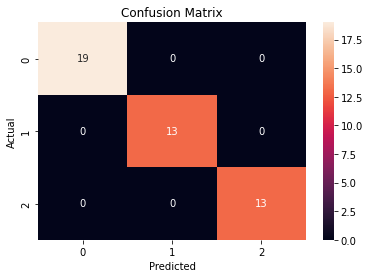

In [84]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d")   #annot to add the value in text, d for integers, or use f for float. 
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Feature Importances:


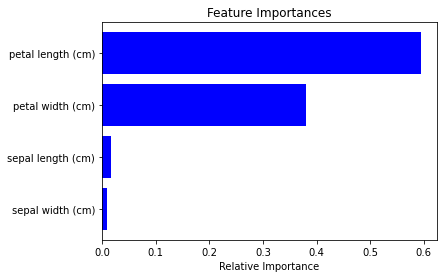

In [80]:
# Feature Importance
print("Feature Importances:")
features = iris.feature_names
importances = gb_clf.feature_importances_
indices = np.argsort(importances)

plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

Visualizing Decision Trees in the Ensemble:


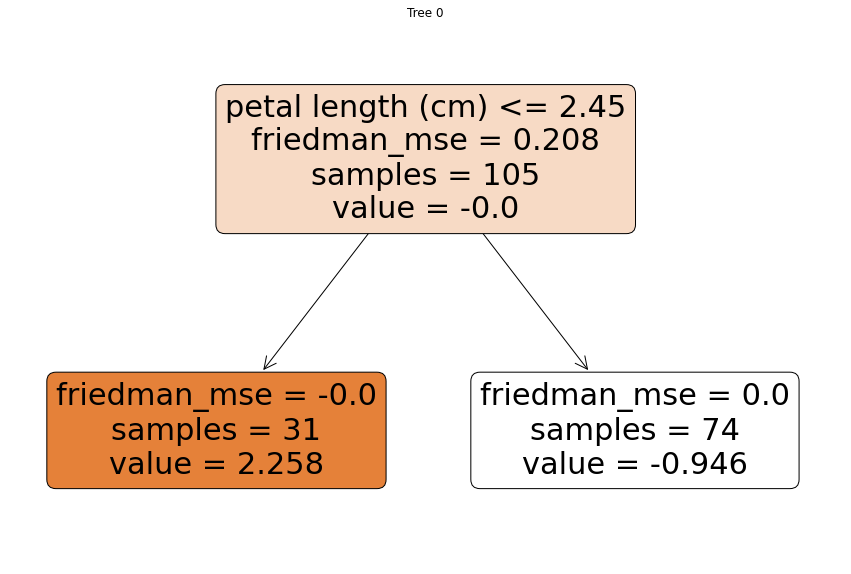

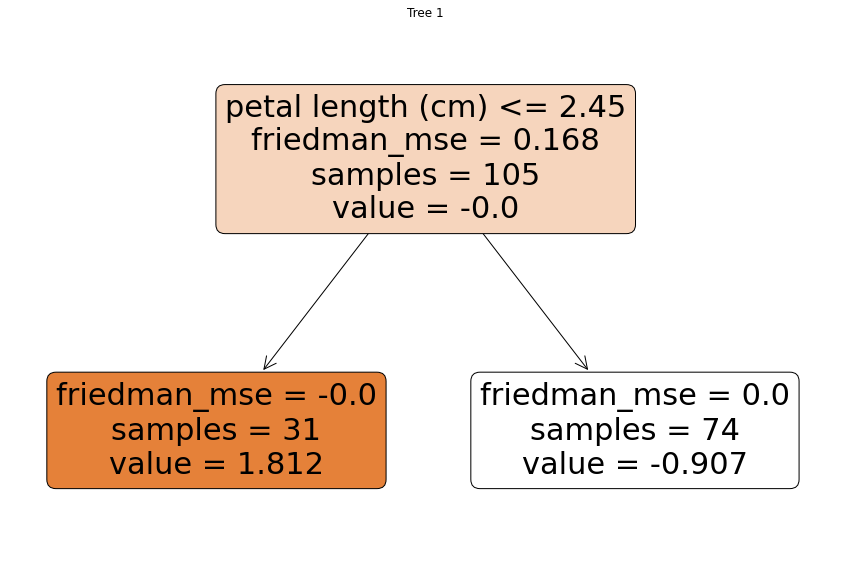

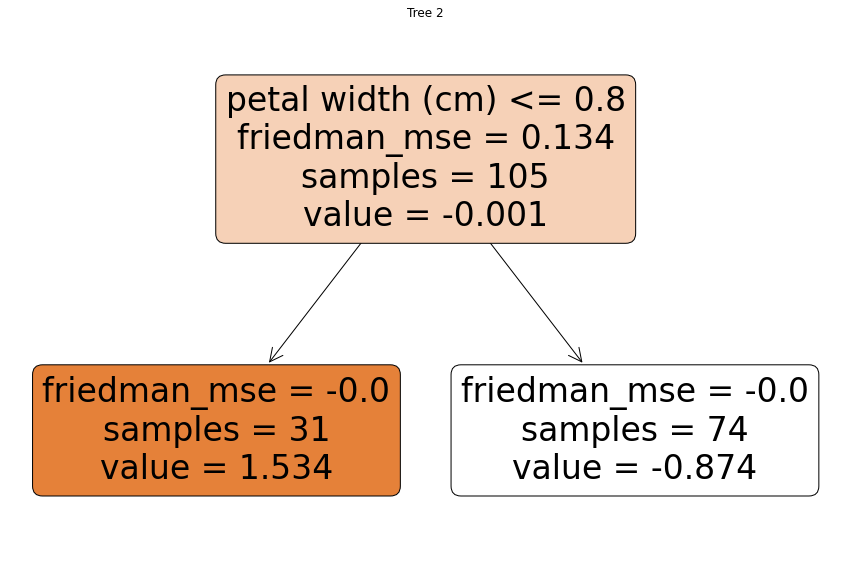

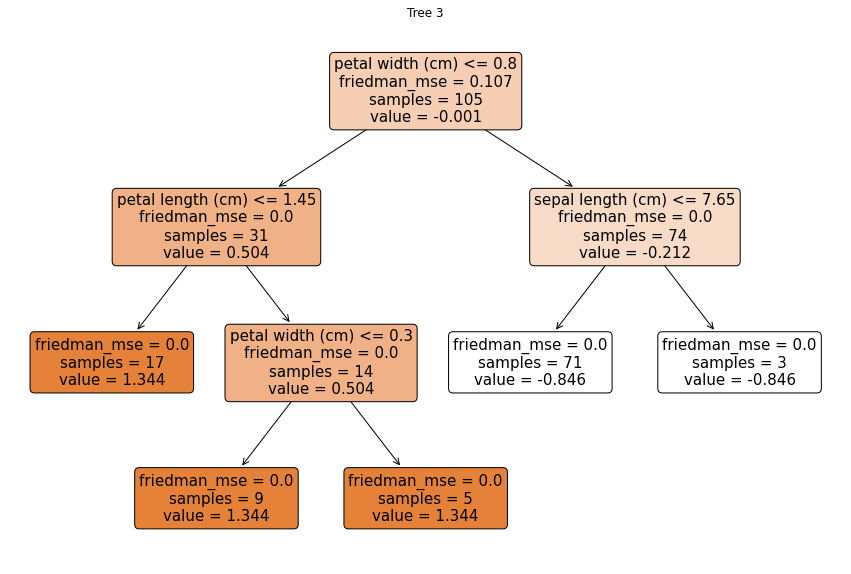

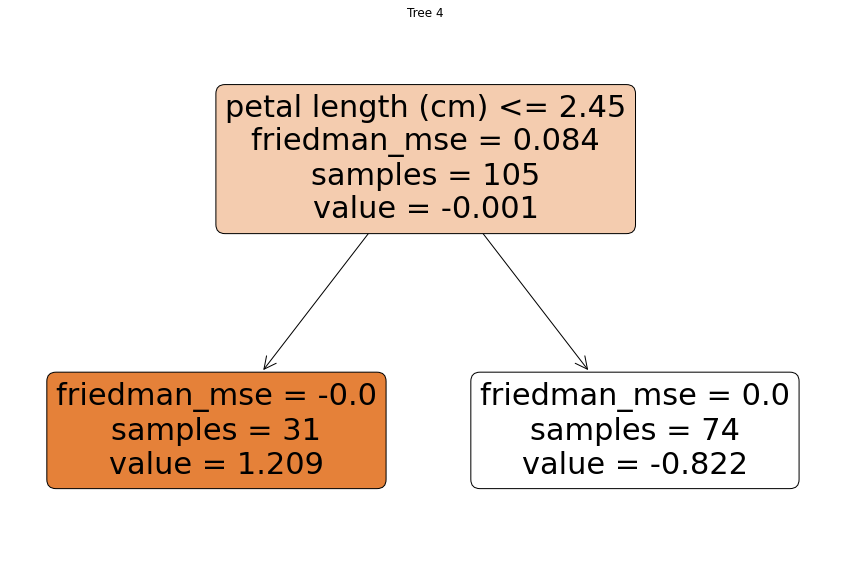

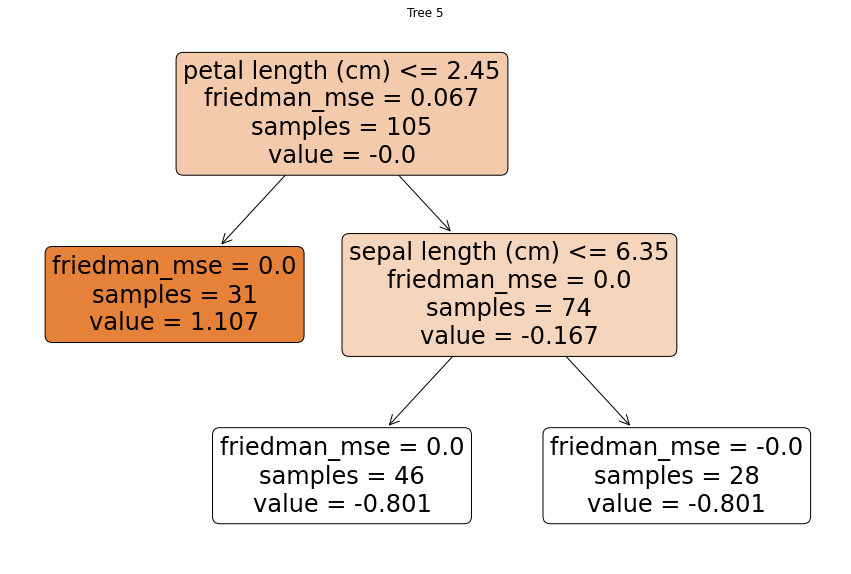

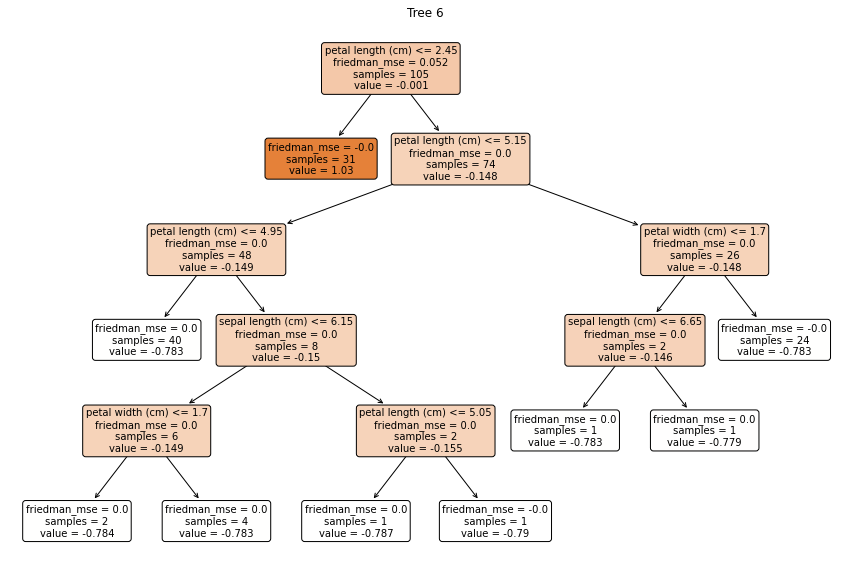

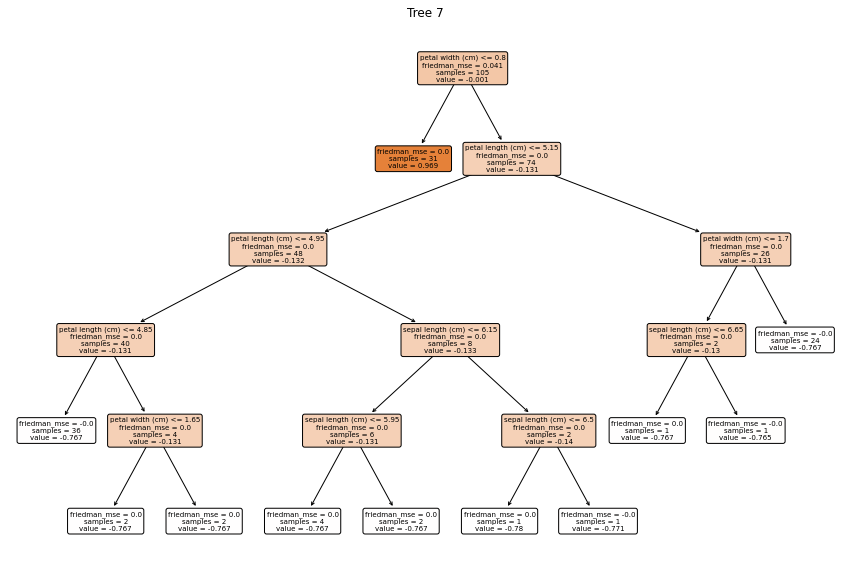

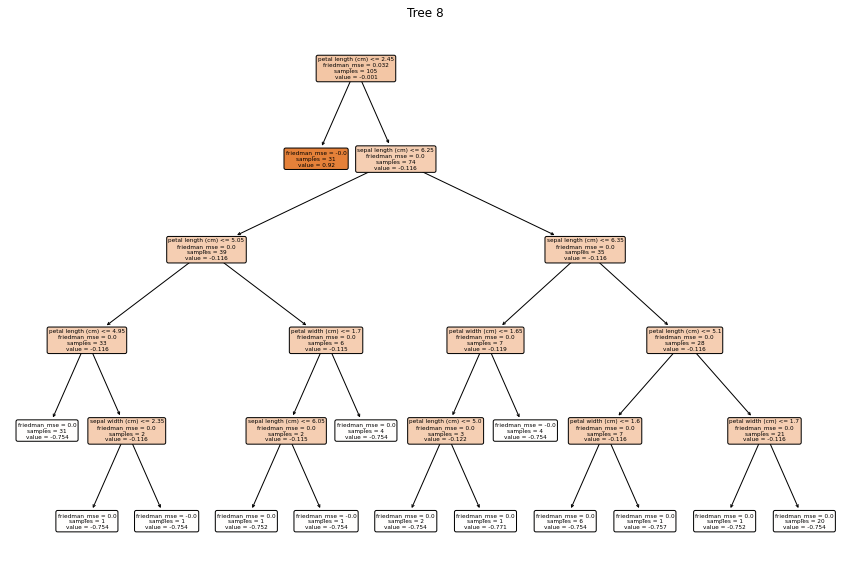

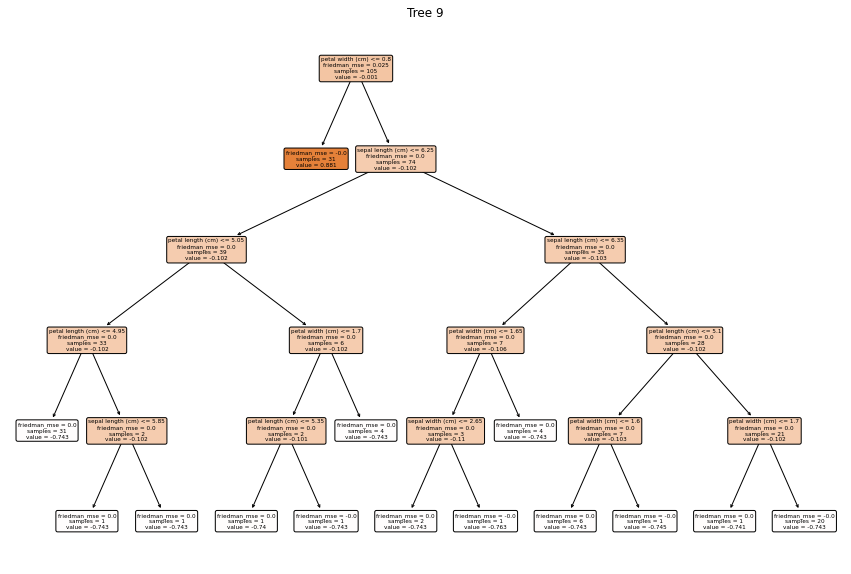

In [85]:
# Plot decision trees in the ensemble (optional, show a few)
from sklearn.tree import plot_tree

print("Visualizing Decision Trees in the Ensemble:")
for i, tree_in_forest in enumerate(gb_clf.estimators_[:10]):   #show till estimator (tree) 10 or whatever
    plt.figure(figsize=(15, 10))
    plot_tree(tree_in_forest[0], filled=True, feature_names=iris.feature_names, 
              class_names=iris.target_names, rounded=True)
    plt.title(f'Tree {i}')
    plt.show()

In [86]:
## Binary Classification with BDT:

In [87]:
# Select only 'setosa' and 'versicolor' for binary classification (classes 0 and 1)
binary_filter = (y == 0) | (y == 1)
X_binary = X[binary_filter]
y_binary = y[binary_filter]    

In [88]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_binary, y_binary, test_size=0.3, random_state=42)

In [94]:
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, verbose=True)

In [95]:
# Train the model
gb_clf.fit(X_train, y_train)

# Predictions
y_pred = gb_clf.predict(X_test)

      Iter       Train Loss   Remaining Time 
         1           1.1930            0.19s
         2           1.0376            0.23s
         3           0.9081            0.21s
         4           0.7987            0.19s
         5           0.7052            0.18s
         6           0.6247            0.18s
         7           0.5549            0.17s
         8           0.4941            0.16s
         9           0.4407            0.15s
        10           0.3938            0.15s
        20           0.1351            0.09s
        30           0.0485            0.06s
        40           0.0177            0.05s
        50           0.0065            0.04s
        60           0.0024            0.03s
        70           0.0009            0.02s
        80           0.0003            0.01s
        90           0.0001            0.01s
       100           0.0000            0.00s


In [96]:
# Model Evaluation
print("Model Evaluation:")
print(classification_report(y_test, y_pred))

Model Evaluation:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        17
           1       1.00      1.00      1.00        13

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



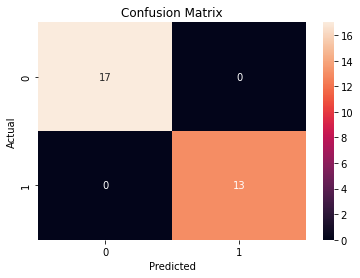

In [97]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Feature Importances:


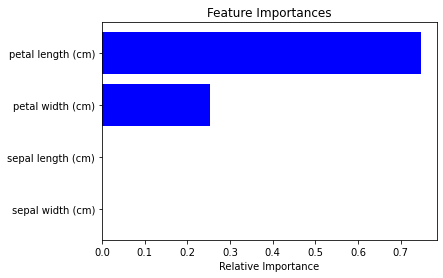

In [100]:
# Feature Importance
print("Feature Importances:")
features = iris.feature_names
importances = gb_clf.feature_importances_
indices = np.argsort(importances)
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

Visualizing Decision Trees in the Ensemble for Binary Classification:


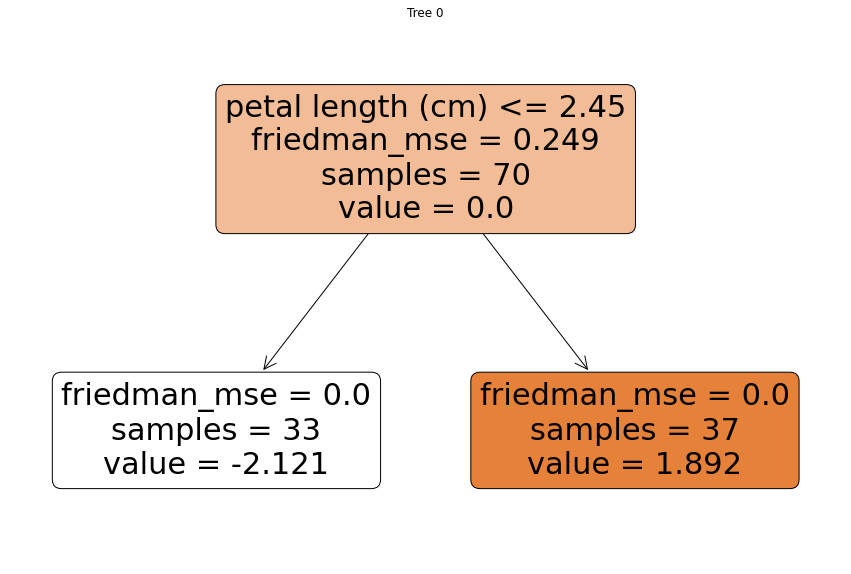

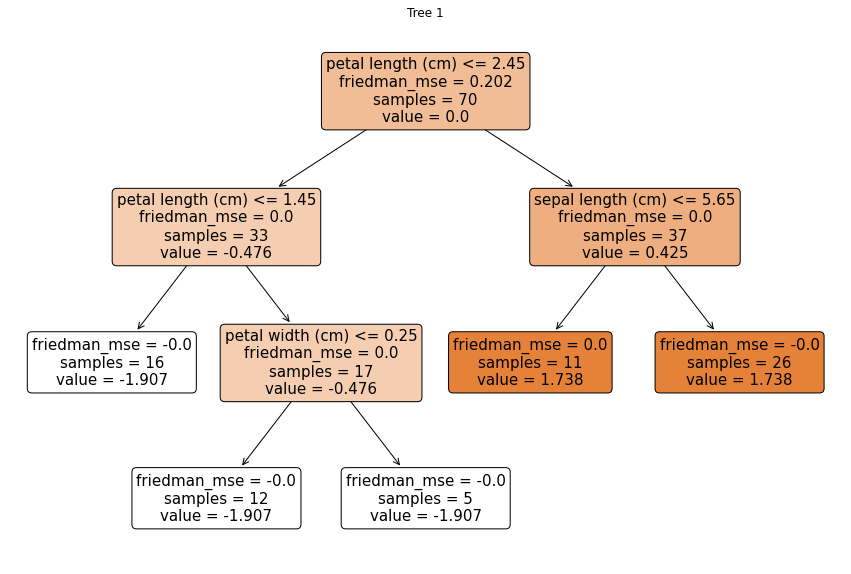

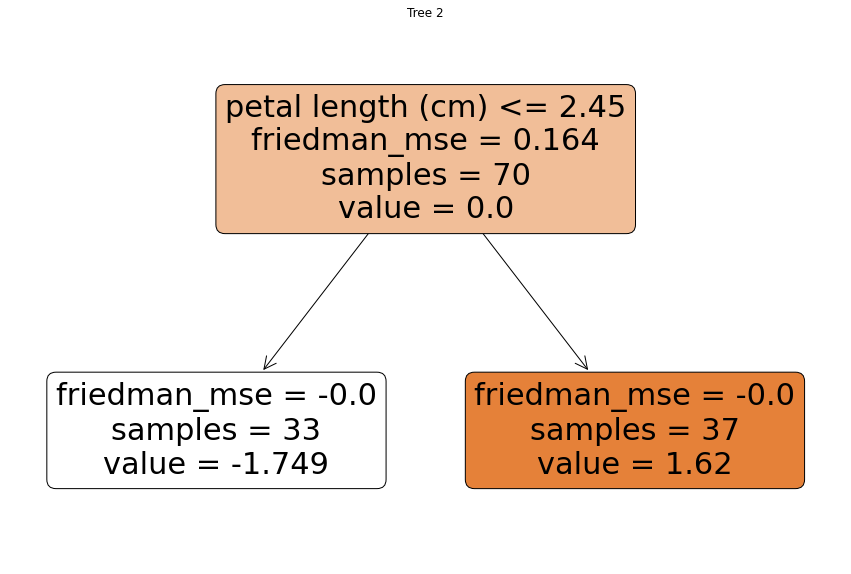

In [103]:
print("Visualizing Decision Trees in the Ensemble for Binary Classification:")
for i, tree_in_forest in enumerate(gb_clf.estimators_[:3]):   #show till estimator (tree) 10 or whatever
    plt.figure(figsize=(15, 10))
    plot_tree(tree_in_forest[0], filled=True, feature_names=iris.feature_names, 
              class_names=iris.target_names, rounded=True)
    plt.title(f'Tree {i}')
    plt.show()

In [126]:
# USING AdaBoost as Classifier

In [105]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

In [106]:
# Load the Iris dataset
iris = datasets.load_iris()
X = iris.data
y = iris.target

In [107]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [118]:
# Initialize the AdaBoost Classifier
# Here, we use a Decision Tree Classifier as the base estimator
ada_clf = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, algorithm="SAMME.R", learning_rate=0.1, random_state=42)

In [119]:
# Train the model
ada_clf.fit(X_train, y_train)

# Predictions
y_pred = ada_clf.predict(X_test)

In [120]:
# Model Evaluation
print("Model Evaluation:")
print(classification_report(y_test, y_pred))

Model Evaluation:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       0.93      1.00      0.96        13
           2       1.00      0.92      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.97        45
weighted avg       0.98      0.98      0.98        45



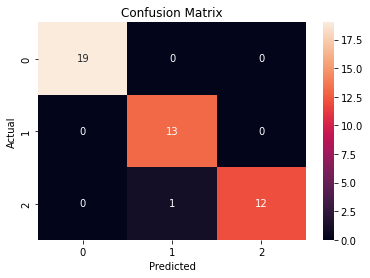

In [121]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Feature Importances:


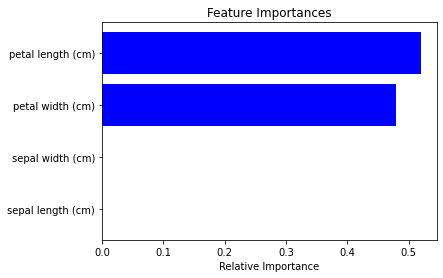

In [122]:
# Feature Importance
print("Feature Importances:")
features = iris.feature_names
importances = ada_clf.feature_importances_
indices = np.argsort(importances)

plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

Visualizing Decision Trees in the Ensemble for Binary Classification:


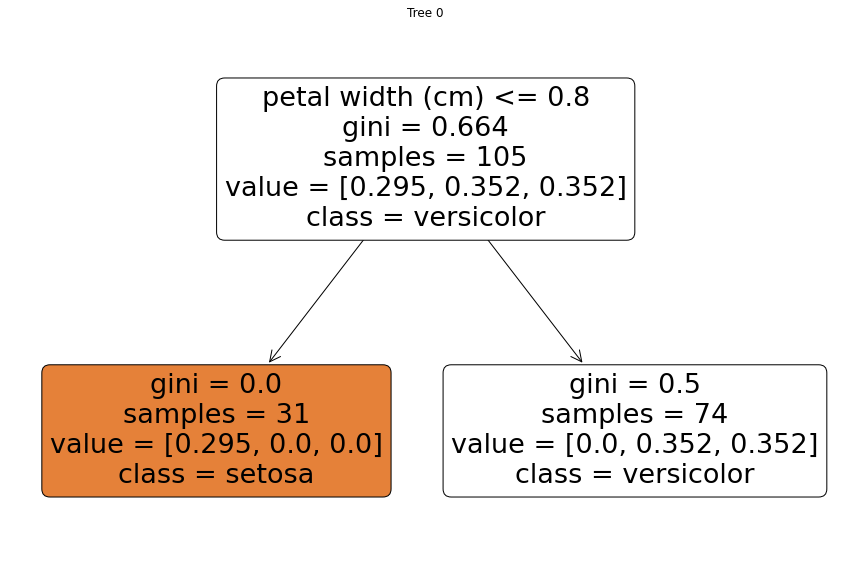

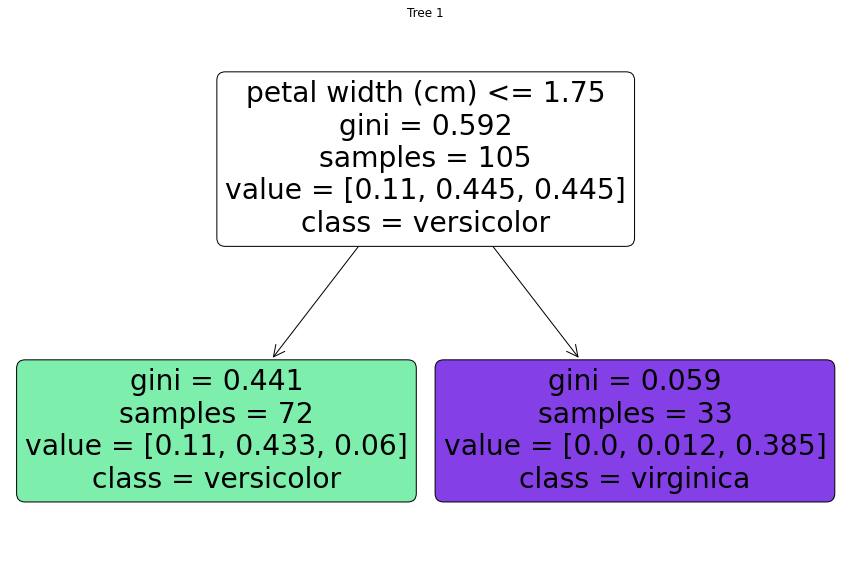

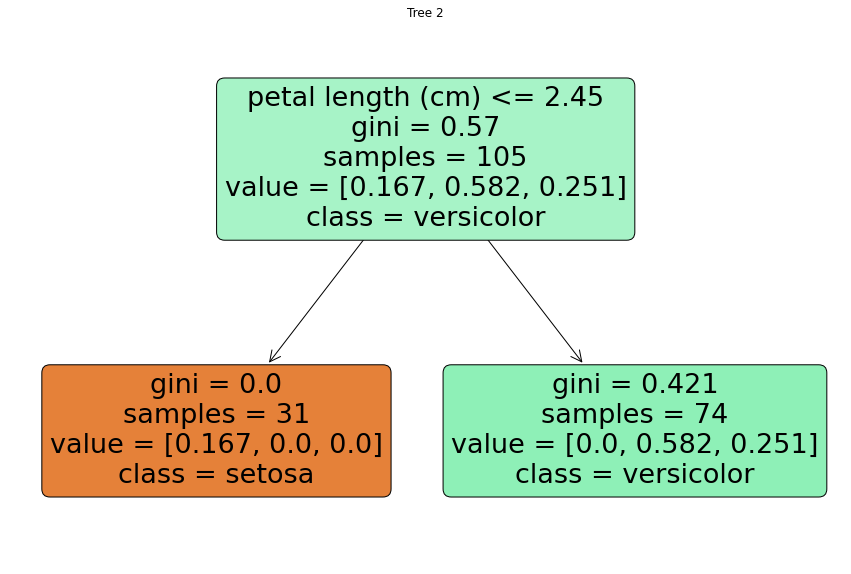

In [125]:
print("Visualizing Decision Trees in the Ensemble for Binary Classification:")
# Unlike Gradient Boosting, where each element in estimators_ is a single-element array containing a tree,
#in AdaBoost, each element in estimators_ is directly a tree.

for i, tree_in_forest in enumerate(ada_clf.estimators_[:3]):   #show till estimator (tree) 10 or whatever
    plt.figure(figsize=(15, 10))
    plot_tree(tree_in_forest, filled=True, feature_names=iris.feature_names,    #no array element, directly the tree
              class_names=iris.target_names, rounded=True)
    plt.title(f'Tree {i}')
    plt.show()